# CampusPulse - EDA & Model Selection

Exploratory analysis of the UCI Student Performance dataset and a comparison
of candidate models. The winning model (Gradient Boosting) is what
`src/train_model.py` trains and saves.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from data_preprocessing import load_data

sns.set_theme(style="whitegrid")
df = load_data()
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Dataset overview

395 students, 33 columns. Target: `G3` (final grade, 0-20). `G1`/`G2` are the
period grades. Everything else describes background, study habits and lifestyle.

In [2]:
print(df.shape)
df.describe().T

(395, 33)


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## 2. How are final grades distributed?

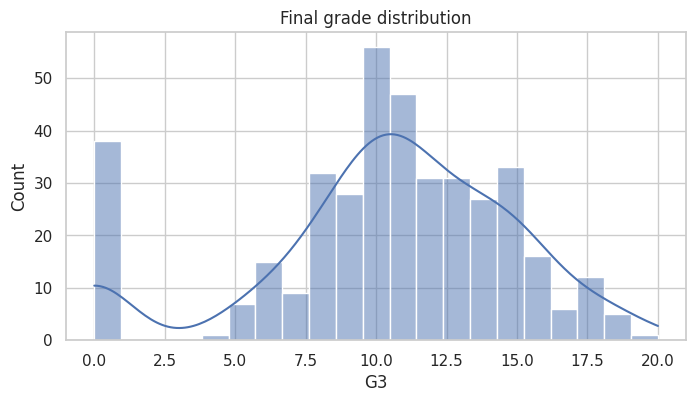

In [3]:
plt.figure(figsize=(8, 4))
sns.histplot(df["G3"], bins=21, kde=True)
plt.title("Final grade distribution")
plt.show()

## 3. What correlates with the final grade?

`G1` and `G2` dominate (they are earlier exams of the same course), followed by
`failures` (negative) and `Medu` / `studytime` (positive).

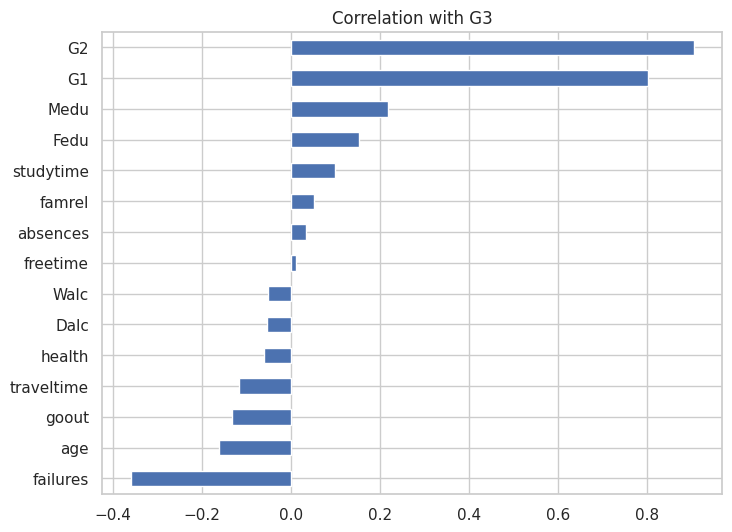

In [4]:
corr = df.select_dtypes(exclude="object").corr()["G3"].sort_values()
corr.drop("G3").plot(kind="barh", figsize=(8, 6), title="Correlation with G3")
plt.show()

## 4. Study time vs final grade

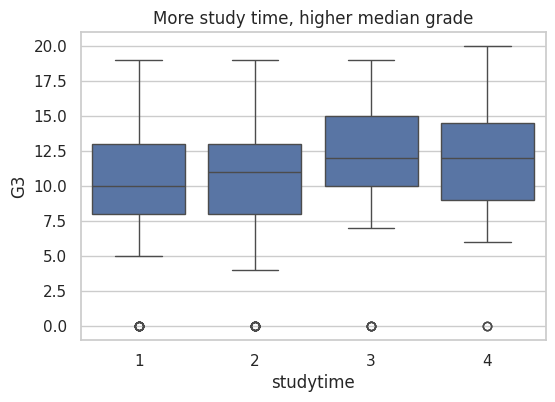

In [5]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("More study time, higher median grade")
plt.show()

## 5. Model comparison

Same preprocessing pipeline for all models; 5-fold cross-validation R².
Gradient Boosting wins and is also easy to explain via feature importances.

In [6]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

from data_preprocessing import build_preprocessor, split_features_target

X, y = split_features_target(df)

candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, model in candidates.items():
    pipe = Pipeline([("preprocess", build_preprocessor(X)), ("model", model)])
    scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
    print(f"{name:20s}  CV R2 = {scores.mean():.3f} +/- {scores.std():.3f}")

Linear Regression     CV R2 = 0.784 +/- 0.061


Random Forest         CV R2 = 0.825 +/- 0.037


Gradient Boosting     CV R2 = 0.824 +/- 0.041


## Takeaways

1. Period grades (`G1`, `G2`) carry most of the signal - the model is best used
   *during* the term, after each period exam.
2. Without midterm grades the model is much weaker (R² ~ 0.25), but `failures`,
   `studytime` and `absences` still give a useful early warning.
3. Gradient Boosting generalizes best here, so CampusPulse uses it for both
   the grade regressor and the at-risk classifier.